# Permit, answer, enforce: the runtime layer of a measured robot

A policy — a VLA, an MPC, an LLM planner, a teleoperator — proposes motion. Something
has to decide whether *this* robot, today, can survive it, and something has to hold
the machine when the answer is no. This tutorial builds that layer on one unit and one
mission: a small mobile manipulator asked to pick up an unfamiliar tote. You will finish
able to ask a per-unit twin a quantitative question (`jaxterity.oracle`), read the
*dispersion* of its answer as honesty rather than noise, enroll an unknown object safely
before touching it (`jaxterity.objects.scene`), and clamp an arbitrary policy's torque to
what the measured unit can actually take (`jaxterity.selfcheck.ReflexController`).

**Reading time** ~35 min · **Runtime** just over 6 minutes end to end (6 min 18–20 s
across runs), measured on an Apple-silicon laptop CPU — the object-enrollment cell is about half of it and everything
else is seconds. No GPU, no hardware.

## Prerequisites

- [`twin_so101.ipynb`](twin_so101.ipynb) — what a per-unit `Twin` is, and why off-body
  physics (servo heat, battery sag) is the part a body-only model cannot see.
- [`selfcheck_demo_lekiwi.ipynb`](selfcheck_demo_lekiwi.ipynb) — the predict-and-veto
  chain this notebook extends: co-processor → `SafetyMonitor` → `preflight`.
- Helpful but not required: [`same_pixels_different_physics.ipynb`](same_pixels_different_physics.ipynb)
  for object identification from joint telemetry.

Everything below runs against `zoo.calibrated("so100")`, whose friction/damping came
from real LeKiwi telemetry, plus representative off-body defaults. Which numbers are
measured and which are representative is called out at each step — that distinction is
the whole point of the layer.

In [1]:
import contextlib
import io
import logging
import os
import sys

if os.path.basename(os.getcwd()) in ("examples", "scripts"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())

with (
    contextlib.redirect_stdout(io.StringIO()),
    contextlib.redirect_stderr(io.StringIO()),
):
    # MuJoCo probes an optional NVIDIA Warp backend on import and prints when it is
    # absent; harmless (MJX falls back to JAX).
    import mujoco  # noqa: F401
    from mujoco import mjx  # noqa: F401

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

logging.disable(logging.INFO)

from jaxonomy.diagnostics import analyze_control_oscillation, analyze_saturation

from jaxterity.calibrate.active import dof_joint_names
from jaxterity.checkup.stability import LEKIWI_BASE, StabilityConstraint, zmp_margins
from jaxterity.objects import (
    PayloadLoopbackLink,
    RigidPayload,
    SemanticPrior,
    enroll_object,
    vet_probe,
)
from jaxterity.oracle import (
    TIP_OVER,
    hold_plan,
    posterior_twins,
    simulate_plan,
    what_if,
)
from jaxterity.selfcheck import (
    ReflexController,
    SafetyEnvelope,
    SafetyMonitor,
    SimplexSwitch,
)
from jaxterity.twin import lekiwi_twin

SEED = 0

# The mission's declared limits. Every number here is an *operator* choice — the layer
# enforces what you declare, it does not invent limits for you.
CEILING_K = 343.15  # servo temperature ceiling, K (70 degC)
BUS_FLOOR_V = 11.0  # brownout floor on the shared 3S bus, V
TORQUE_FRAC = 0.9  # fraction of each joint's effort limit we allow

# Two arm poses, in DOF order (rad). The model's zero pose reaches forward — the pose
# that rocked a real LeKiwi off its rear wheel on 2026-07-28.
POSE_TUCKED = (0.0, -1.2, -0.8, 0.0, 0.0, 0.0)
POSE_EXTENDED = (0.0, 0.0, 0.0, 0.0, 0.0, 0.0)

print(f"numpy {np.__version__} · mujoco {mujoco.__version__}")

numpy 2.4.6 · mujoco 3.10.0


## 1. The mission, and the three questions a camera cannot answer

A LeKiwi — a 6-DOF SO-101 arm on a three-wheeled mobile base — is told: *pick up that
tote and carry it to the bench*. A vision model can say the tote is a plastic crate
roughly 10 × 8 × 6 cm. It cannot say:

1. **Will the servos survive the carry?** Heat depends on held torque squared, not on
   what the object looks like.
2. **Will the base tip?** That depends on the object's mass and where the arm holds it —
   on a small base with a high payload-to-robot mass ratio, this is the binding
   constraint, and no joint-limit check sees it.
3. **What if the guess is wrong?** A "plastic crate" that turns out to be full of bolts
   is the same pixels and a different robot problem.

Three organs answer these, and they are genuinely different things:

| Organ | Simulates to… | Timescale | Mandatory? |
|---|---|---|---|
| MPC / policy | **choose** an action | ms | userland's business |
| Gate (`preflight`, `SafetyMonitor`) | **permit** a chunk | s | yes — it is the safety boundary |
| **Oracle** (`jaxterity.oracle`) | **answer** a question | s | no — a service userland calls |
| **Reflex** (`ReflexController`) | **enforce**, every tick | ms | yes — it is what runs on a veto |

This notebook builds the last two and shows them composing with the first two, in the
order a real mission hits them: ask before you act (§3–4), enroll the object you are
about to lift (§5), and keep a filter in the torque path while you do it (§6).

## 2. Symbols and the three equations this notebook rests on

| Symbol | Meaning | Unit |
|---|---|---|
| $\mathbf q, \dot{\mathbf q}$ | joint positions, velocities | rad, rad/s |
| $\boldsymbol\tau$ | commanded generalized force | N·m |
| $T_i$ | servo $i$ winding/case temperature | K |
| $T_{\text{amb}}$, $T_{\text{ceil}}$ | ambient, declared ceiling | K |
| $C_{th}, R_{th}, k_{pwr}$ | thermal capacitance, resistance, torque²→power gain | J/K, K/W, W/(N·m)² |
| $\tau_{th} = R_{th} C_{th}$ | servo thermal time constant | s |
| $V$ | shared-bus voltage | V |
| $h(\mathbf x)$ | barrier value — safe where positive | mixed |
| $\alpha$ | class-$\mathcal K$ gain on a barrier | 1/s |
| $\boldsymbol\theta$ | the unit's fitted parameters | mixed |

**(a) A barrier and its class-$\mathcal K$ condition.** Given a scalar $h(\mathbf x)$ that
is non-negative exactly on the states we accept, and dynamics
$\dot{\mathbf x} = f(\mathbf x, \boldsymbol\tau)$, the control-barrier condition is

$$\dot h(\mathbf x, \boldsymbol\tau) \;+\; \alpha\, h(\mathbf x) \;\ge\; 0 . \tag{1}$$

Read it as a speed limit on *approaching* the edge: $h$ may shrink no faster than
$\alpha h$, so $h$ decays at worst exponentially and never reaches zero in finite time.
$\alpha$ has units of 1/s, which is the first hint that it has to match the timescale of
whatever $h$ measures — a point that bites us in §6.

**(b) Making a position limit relative-degree one.** Torque moves $\ddot q$, not $q$, so a
naive $h = q^{\max} - q$ has no $\boldsymbol\tau$ in $\dot h$ and (1) is vacuous. Subtract
the distance the joint needs in order to stop, at a declared braking capability $a$:

$$h_{\text{up},i} \;=\; \bigl(q_i^{\max} - \delta\bigr) \;-\; q_i \;-\; \frac{\left[\dot q_i\right]_+^2}{2\,a_i}. \tag{2}$$

Units check: $[\text{rad}] - [\text{rad}] - [(\text{rad/s})^2 / (\text{rad/s}^2)] = \text{rad}$. ✓
Now $\dot h$ contains $\ddot q$, hence $\boldsymbol\tau$, and (1) is one linear inequality
per joint. (This is the Acc-CBF-QP shape; see the references.)

**(c) The servo's thermal model.** A single-node servo obeys
$C_{th}\dot T = k_{pwr}\tau^2 - (T - T_{\text{amb}})/R_{th}$, which rearranges into a form
worth memorizing:

$$\dot T \;=\; \frac{T_{ss}(\tau) - T}{\tau_{th}}, \qquad T_{ss}(\tau) = T_{\text{amb}} + k_{pwr} R_{th}\,\tau^2 . \tag{3}$$

$[\,\text{W/(N·m)}^2 \cdot \text{K/W} \cdot (\text{N·m})^2] = \text{K}$ ✓ — $T_{ss}$ is the
temperature the servo *ends up at* if you hold $\tau$ forever. Everything the gate, the
oracle, and the reflex say about heat is a statement about $T_{ss}$ and how fast you
approach it.

## 3. The unit under test

`lekiwi_twin` composes the calibrated arm with the off-body physics of one physical
unit: a per-servo thermal node and a shared battery. Two honesty notes, both of which
shape what we may claim later:

- The **body** calibration is real — per-joint friction and damping fitted from LeKiwi
  telemetry — and the **battery** Thévenin parameters are fitted from a real
  aggregate-load capture.
- The **thermal** parameters are *representative*, not fitted: the committed temperature
  traces are 1 °C-quantized and far shorter than the servo's thermal time constant, so
  they do not identify the model (this is a documented gap, not an oversight).
- The zoo has no LeKiwi *base* model, so the base enters as a **declared profile**
  (`LEKIWI_BASE`: support polygon, mass, mount transform) rather than as bodies in the
  dynamics.

In [2]:
twin = lekiwi_twin("LK-0001")
n = twin.n_servos
joint_names = dof_joint_names(twin.robot)

print(f"serial            : {twin.serial}")
print(f"servos (DOFs)     : {n}  {joint_names}")
print(
    f"battery on the bus: {twin.has_battery}  (V_oc = {float(twin.V_oc):.3f} V, "
    f"R_int = {float(twin.R_int):.4f} ohm)"
)
print(
    f"thermal leaves    : C_th = {float(twin.C_th[0]):.0f} J/K, "
    f"R_th = {float(twin.R_th[0]):.0f} K/W, k_pwr = {float(twin.k_pwr[0]):.0f} W/(N.m)^2"
)
print(
    f"thermal time const: tau_th = R_th * C_th = "
    f"{float(twin.R_th[0]) * float(twin.C_th[0]):.0f} s"
)
print(f"attestation handle: {twin.attestation_handle[:16]}...")
print()
print("fitted body parameters (real telemetry):")
for name in ("shoulder_pan", "elbow_flex"):
    j = twin.robot.joint_map[name]
    print(
        f"  {name:13s} damping = {float(j.damping):.4f} N.m.s/rad, "
        f"friction = {float(j.friction):.4f} N.m"
    )

serial            : LK-0001
servos (DOFs)     : 6  ('shoulder_pan', 'shoulder_lift', 'elbow_flex', 'wrist_flex', 'wrist_roll', 'gripper')
battery on the bus: True  (V_oc = 12.166 V, R_int = 0.0653 ohm)
thermal leaves    : C_th = 15 J/K, R_th = 4 K/W, k_pwr = 6 W/(N.m)^2
thermal time const: tau_th = R_th * C_th = 60 s
attestation handle: 36a21b681415d881...

fitted body parameters (real telemetry):
  shoulder_pan  damping = 0.4150 N.m.s/rad, friction = 0.0147 N.m
  elbow_flex    damping = 0.0674 N.m.s/rad, friction = 0.0046 N.m


The unit as built carries *point estimates*. An oracle answer's honesty comes from the
covariance attached to those estimates, so we attach one explicitly. In a production
flow this comes from the fit itself (`fit_servo_thermal` → `Twin.with_thermal(...)`); here
we **declare** a standard deviation of 0.8 K/W on $R_{th}$ and 1.2 W/(N·m)² on $k_{pwr}$ —
about 20 % — which is a fair stand-in for a thermal fit this unit does not yet have.

> **Pitfall:** a wide band because you *declared* one is not the same as a wide band you
> *measured*. The oracle reports what it was given. Where a twin carries no covariance at
> all, it reports a zero-width band and says so in the answer's `detail`, rather than
> implying a confidence it has not earned.

In [3]:
R_TH_STD = 0.8  # K/W
K_PWR_STD = 1.2  # W/(N.m)^2

unit = twin.with_thermal(
    param_uncertainty=(
        ("offbody.R_th", tuple([R_TH_STD**2] * n)),  # marginal *variance*, not std
        ("offbody.k_pwr", tuple([K_PWR_STD**2] * n)),
    )
)
envelope = SafetyEnvelope(
    temp_ceiling_k=CEILING_K,
    bus_floor_v=BUS_FLOOR_V,
    torque_margin_frac=TORQUE_FRAC,
)

print("leaves the posterior covers:", sorted(unit.uncertainty()))
print(f"R_th   = {float(unit.R_th[0]):.2f} +/- {R_TH_STD:.2f} K/W")
print(f"k_pwr  = {float(unit.k_pwr[0]):.2f} +/- {K_PWR_STD:.2f} W/(N.m)^2")
print(
    f"envelope: ceiling {CEILING_K:.2f} K, bus floor {BUS_FLOOR_V:.1f} V, "
    f"torque <= {TORQUE_FRAC:.0%} of effort limit"
)
print(
    f"attaching a fit's covariance does NOT change identity: handle unchanged = "
    f"{unit.attestation_handle == twin.attestation_handle}"
)

leaves the posterior covers: ['offbody.R_th', 'offbody.k_pwr']
R_th   = 4.00 +/- 0.80 K/W
k_pwr  = 6.00 +/- 1.20 W/(N.m)^2
envelope: ceiling 343.15 K, bus floor 11.0 V, torque <= 90% of effort limit
attaching a fit's covariance does NOT change identity: handle unchanged = True


## 4. The oracle: ask the unit, get a number and a spread

The gate answers *may I?*; the oracle answers *what happens?*. Both roll the same twin
forward — the difference is that the oracle rolls it forward **once per posterior draw**
and reports the distribution:

$$\boldsymbol\theta^{(k)} \sim \mathcal N(\hat{\boldsymbol\theta}, \Sigma), \qquad
\text{outcome}^{(k)} = \mathcal{G}\bigl(\text{rollout}(\text{plan};\boldsymbol\theta^{(k)})\bigr), \tag{4}$$

where $\mathcal{G}$ is the same `SafetyMonitor` the gate uses. `jax.vmap` evaluates all
draws in one traced pass, so the spread costs about what a single rollout costs.

Our first question is the mission's core: *can this unit hold the tote at 1.3 N·m per
joint for the carry?* Below the ceiling we would say yes; above it, no. The interesting
case — and the one a point estimate hides — is when the ceiling lands *inside* the
posterior.

In [4]:
HOLD_TAU = 1.2  # N.m per joint, the carry's sustained holding torque
N_DRAWS = 24

carry = hold_plan(
    "carry the tote", unit, [HOLD_TAU] * n, n_steps=40, dt=0.005, q0=POSE_TUCKED
)
answer = simulate_plan(unit, carry, envelope, n_draws=N_DRAWS, seed=SEED)

print(answer.summary())
print()
for band in answer.margins:
    print("  ", band.summary())
print()
print(f"time to thermal breach at this hold: {answer.time_to_breach_s:.0f} s")
print(f"answer binds to twin {answer.twin_handle[:16]}...")

carry the tote: VETO (46% of 24 draws pass; binding servo_temperature) — servo_temperature: worst 369.1 K (median 344.1, band [333.8, 359.8]); posterior over R_th, k_pwr (24 draws). Worst case is what a gate would enforce; the pass fraction says how much of it is this unit's own parameter uncertainty.

   servo_temperature: worst 369.1 K (median 344.1, band [333.8, 359.8])
   bus_voltage: worst 11.46 V (median 11.46, band [11.46, 11.46])
   torque: worst 0.12 fraction (median 0.12, band [0.12, 0.12])

time to thermal breach at this hold: 97 s
answer binds to twin 36a21b681415d881...


Read the two headline numbers together, because either alone misleads:

- `outcome` is the **worst case** over the posterior — what a gate would enforce if this
  unit sits at the unlucky end of its own uncertainty.
- `pass_fraction` says **how much of that verdict is ignorance**. A veto at 0 % is
  physics: no plausible version of this unit survives. A veto at 60 % means the fit is
  too loose to tell, and the honest response is to *measure* — a longer thermal capture —
  not to derate on a guess.

That is the margin dividend in one line: uncertainty is paid for in conservatism, so
tightening a parameter interval buys back permitted performance.

posterior over R_th, k_pwr (24 draws)


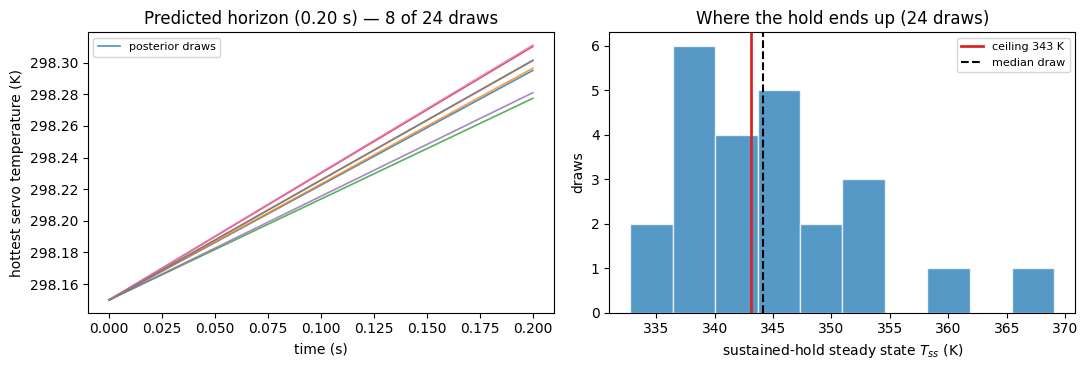

draws whose sustained hold exceeds the ceiling: 54%
T_ss median 344.1 K, range [332.8, 369.1] K


In [5]:
# The same posterior, unpacked: where does each draw's sustained-hold steady state land?
draws, note = posterior_twins(unit, N_DRAWS, seed=SEED)
print(note)

tau_vec = np.full(n, HOLD_TAU)
T_ss = np.array(
    [
        float((d.T_amb + np.asarray(d.k_pwr) * np.asarray(d.R_th) * tau_vec**2).max())
        for d in draws
    ]
)
# Short-horizon predicted trajectories, one per draw (what the co-processor would see).
rollouts = [
    np.asarray(
        d.rollout(
            jnp.asarray(carry.q0),
            jnp.asarray(carry.qd0),
            jnp.asarray(carry.T0),
            jnp.asarray(carry.tau),
            carry.dt,
        ).temperature
    ).max(axis=1)
    for d in draws[:8]
]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
t_ms = np.arange(len(rollouts[0])) * carry.dt
for k, tr in enumerate(rollouts):
    axes[0].plot(
        t_ms, tr, lw=1.2, alpha=0.8, label="posterior draws" if k == 0 else None
    )
axes[0].set_xlabel("time (s)")
axes[0].set_ylabel("hottest servo temperature (K)")
axes[0].set_title(
    f"Predicted horizon ({carry.duration_s:.2f} s) — 8 of {N_DRAWS} draws"
)
axes[0].legend(loc="upper left", fontsize=8)

axes[1].hist(T_ss, bins=10, color="tab:blue", alpha=0.75, edgecolor="white")
axes[1].axvline(CEILING_K, color="tab:red", lw=2, label=f"ceiling {CEILING_K:.0f} K")
axes[1].axvline(float(np.median(T_ss)), color="k", ls="--", lw=1.5, label="median draw")
axes[1].set_xlabel(r"sustained-hold steady state $T_{ss}$ (K)")
axes[1].set_ylabel("draws")
axes[1].set_title(f"Where the hold ends up ({N_DRAWS} draws)")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

over = float((T_ss > CEILING_K).mean())
print(f"draws whose sustained hold exceeds the ceiling: {over:.0%}")
print(
    f"T_ss median {np.median(T_ss):.1f} K, range [{T_ss.min():.1f}, {T_ss.max():.1f}] K"
)

*Figure 1 — left: the hottest servo's predicted temperature over the 0.2 s control
horizon, one line per posterior draw; the lines barely separate, because 0.2 s is
nothing next to a 60 s thermal time constant. Right: the same draws' sustained-hold
steady state $T_{ss}$ (equation 3) against the declared ceiling in red.*

The two panels are the argument for the oracle. A short-horizon forecast — what a
real-time monitor sees — says almost nothing about a thermal ceiling, because the servo
has barely started heating. The steady state, which is analytic and free, straddles the
ceiling: some plausible versions of this unit cook on this carry and some do not. That
split is the answer, and a single-parameter simulator cannot express it.

## 5. `what_if`: choosing a technique, with the base in the loop

The second mission question — *will it tip?* — needs physics the joint-limit check
cannot see. `simulate_plan(..., base=LEKIWI_BASE)` adds the quasi-dynamic zero-moment
point of the *realized* motion:

$$x_{\text{zmp}} \;=\; \frac{\sum_i m_i\left[x_i\left(\ddot z_i + g\right) - z_i \ddot x_i\right]}{\sum_i m_i \left(\ddot z_i + g\right)}, \tag{5}$$

and likewise for $y$; the margin is the signed distance from that point to the edge of
the wheel support polygon (positive inside). Note what enters: **accelerations**. A pose
decides where the ZMP sits at rest; how briskly you move decides how far it swings.

`what_if` runs several candidates on the *same* posterior draws, so the ranking reflects
the plans and not the sampling.

In [6]:
brisk = hold_plan("brisk lift", unit, [0.30] * n, n_steps=30, dt=0.005, q0=POSE_TUCKED)
gentle = hold_plan(
    "gentle lift", unit, [0.05] * n, n_steps=30, dt=0.005, q0=POSE_TUCKED
)

comparison = what_if(
    unit, [brisk, gentle], envelope, base=LEKIWI_BASE, n_draws=4, seed=SEED
)

print(f"ranking (best first): {comparison.ranking}")
print(f"why: {comparison.detail}")
print()
for a in comparison.answers:
    tip = a.margin(TIP_OVER)
    print(
        f"{a.question:12s} {a.outcome.upper():7s} binding={a.binding_constraint:18s} "
        f"tip-over worst = {tip.worst * 1000:6.1f} mm  (floor "
        f"{LEKIWI_BASE.margin_min_m * 1000:.0f} mm)"
    )

ranking (best first): ('gentle lift', 'brisk lift')
why: gentle lift wins on servo_temperature (100% of draws pass) over brisk lift (0%, binding tip_over)

brisk lift   VETO    binding=tip_over           tip-over worst =   -5.6 mm  (floor 20 mm)
gentle lift  PASS    binding=servo_temperature  tip-over worst =   31.9 mm  (floor 20 mm)


The brisk lift is vetoed and the gentle one passes, and they are vetoed on *different*
grounds than a joint check would use: both stay far from every joint limit, both are
thermally trivial, and one of them still puts the ZMP outside the support polygon.

Where does that margin come from? Two things: the pose the arm holds, and the
accelerations it commands. The next cell separates them — same gentle command, two start
poses.

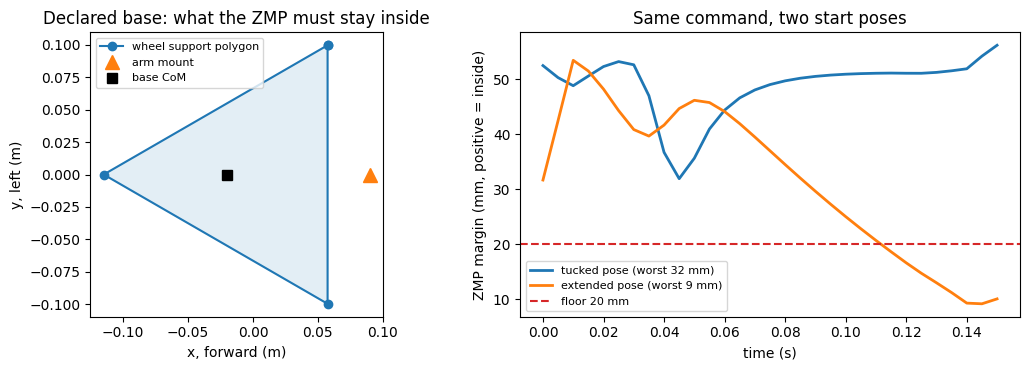

tucked   : start   52.5 mm, worst   31.9 mm
extended : start   31.7 mm, worst    9.2 mm  -> below the floor


In [7]:
def zmp_trace(pose, tau_cmd=0.05, n_steps=30, dt=0.005):
    """Signed ZMP margin (mm) along the motion the twin actually realizes."""
    plan = hold_plan("probe", unit, [tau_cmd] * n, n_steps=n_steps, dt=dt, q0=pose)
    roll = unit.rollout(
        jnp.asarray(plan.q0),
        jnp.asarray(plan.qd0),
        jnp.asarray(plan.T0),
        jnp.asarray(plan.tau),
        plan.dt,
    )
    margins = zmp_margins(
        twin.robot, np.asarray(roll.q), plan.dt, joint_names, LEKIWI_BASE
    )
    return np.arange(len(margins)) * plan.dt, margins * 1000.0


t_tuck, m_tuck = zmp_trace(POSE_TUCKED)
t_ext, m_ext = zmp_trace(POSE_EXTENDED)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
poly = np.asarray(LEKIWI_BASE.support_polygon_xy + (LEKIWI_BASE.support_polygon_xy[0],))
axes[0].plot(
    poly[:, 0], poly[:, 1], "o-", color="tab:blue", label="wheel support polygon"
)
axes[0].fill(poly[:, 0], poly[:, 1], color="tab:blue", alpha=0.12)
axes[0].plot(
    *LEKIWI_BASE.arm_mount_xyz[:2], "^", color="tab:orange", ms=10, label="arm mount"
)
axes[0].plot(*LEKIWI_BASE.base_com_xyz[:2], "s", color="k", ms=7, label="base CoM")
axes[0].set_aspect("equal")
axes[0].set_xlabel("x, forward (m)")
axes[0].set_ylabel("y, left (m)")
axes[0].set_title("Declared base: what the ZMP must stay inside")
axes[0].legend(fontsize=8, loc="upper left")

axes[1].plot(t_tuck, m_tuck, lw=2, label=f"tucked pose (worst {m_tuck.min():.0f} mm)")
axes[1].plot(t_ext, m_ext, lw=2, label=f"extended pose (worst {m_ext.min():.0f} mm)")
axes[1].axhline(
    LEKIWI_BASE.margin_min_m * 1000,
    color="tab:red",
    ls="--",
    label=f"floor {LEKIWI_BASE.margin_min_m * 1000:.0f} mm",
)
axes[1].set_xlabel("time (s)")
axes[1].set_ylabel("ZMP margin (mm, positive = inside)")
axes[1].set_title("Same command, two start poses")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f"tucked   : start {m_tuck[0]:6.1f} mm, worst {m_tuck.min():6.1f} mm")
print(
    f"extended : start {m_ext[0]:6.1f} mm, worst {m_ext.min():6.1f} mm  "
    f"-> {'below' if m_ext.min() < LEKIWI_BASE.margin_min_m * 1000 else 'above'} the floor"
)

*Figure 2 — left: the declared LeKiwi support polygon (two front wheels, one rear), the
arm mount at the front edge, and the base centre of mass. Right: the ZMP margin along
the same gentle command from two start poses; the red line is the profile's pass/fail
floor.*

Look at where the arm mount sits in the left panel: at $x = 9$ cm, **ahead of the front
wheel line** at $x = 5.75$ cm — outside the polygon entirely. Every kilogram the arm
carries forward of that point is levering the base about its front wheels, which is why
pose dominates here and why reaching forward is expensive. This is not a subtlety we
invented; it is the 2026-07-28 hardware finding that motivated the tip-over gate, with
the declared profile reproducing it.

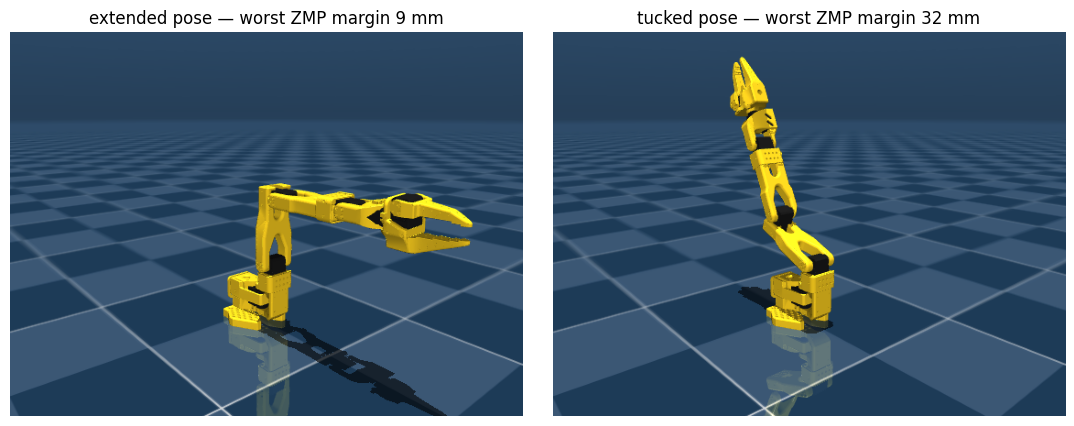

In [8]:
import examples._robot_render as R  # noqa: E402  (the repo's post-hoc renderer)

renderer = R.TrajectoryRenderer("so101_mjcf", twin.robot.to_mjcf(), size=(560, 420))
frames = renderer.render(
    np.array([POSE_EXTENDED, POSE_TUCKED]),
    camera={
        "distance": 0.78,
        "azimuth": 140,
        "elevation": -14,
        "lookat": (0.05, 0.0, 0.18),
    },
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, frame, (label, margin) in zip(
    axes, frames, [("extended", m_ext.min()), ("tucked", m_tuck.min())]
):
    ax.imshow(frame)
    ax.set_axis_off()
    ax.set_title(f"{label} pose — worst ZMP margin {margin:.0f} mm")
fig.tight_layout()
plt.show()

*Figure 3 — post-hoc MuJoCo renders (kinematics only, no physics) of the two poses whose
margins Figure 2 compares. Left: the model's zero pose, reaching forward past the front
wheels. Right: the tucked pose, mass stacked over the base.*

Everything so far assumed we knew what the arm was holding — in fact it was holding
nothing at all. Time to fix that.

## 6. Enrolling an unknown object: guess, vet, heft, re-attest

Here is the chicken-and-egg problem. To know whether lifting the tote is safe, we need
its mass. To measure its mass with the arm, we have to lift it. The escape is to make
the *guess* do bounded work:

1. **Perceive.** A vision model's sentence — "plastic crate, about 10 × 8 × 6 cm" —
   becomes a mass bracket. With material density $\rho \in [\rho_{lo}, \rho_{hi}]$, box
   volume $V$, and a fill fraction $\phi \in [\phi_{lo}, \phi_{hi}]$:

   $$m \in \left[\rho_{lo} V \phi_{lo},\; \rho_{hi} V \phi_{hi}\right]. \tag{6}$$

   Wide on purpose. The bracket's job is to exclude "40 kg", not to be precise.

2. **Vet the probe against the bracket's worst case.** Simulate the candidate heft with
   the *heaviest* object the bracket allows and require the tip-over margin to clear the
   floor. You never need the true mass to probe safely — only an upper bound.

3. **Heft.** Run the vetted probe; the arm's own calibrated dynamics are the force scale
   that makes the object's absolute mass identifiable. The same prior seeds the fit
   (a good starting point escapes inertial identification's bad local minima) and bounds
   it (the search cannot leave the bracket).

4. **Re-attest.** Weld the fitted object onto the twin. The loaded unit is a *different
   attested configuration* — a pre-flight pass on the empty arm does not vouch for it.

5. **Vet the technique** on the loaded unit, with the tip-over screen active.

`enroll_object` runs all five. The heft below is simulated: `PayloadLoopbackLink` plants
a known mass (0.42 kg) and replays the probe through the payload-attached model, so we
can check that the pipeline recovers a number we know. Swap in `ReplayLink` over a real
capture and the same code consumes hardware telemetry.

In [9]:
PLANTED_MASS_KG = 0.42  # what is really in the gripper; the pipeline does not know it

payload = RigidPayload("gripper_frame_link", mass=0.1, name="tote")
prior = SemanticPrior.from_material(
    "small plastic tote, ~10x8x6 cm",
    "plastic",
    (0.10, 0.08, 0.06),
    source="vlm/tutorial",
    confidence=0.6,
)

lo, hi = prior.mass_kg
print(f"vision prior : {prior.label!r} (source {prior.source!r})")
print(f"mass bracket : [{lo:.3f}, {hi:.3f}] kg   (factor {hi / lo:.1f} wide)")
print(
    f"fit seed     : {prior.seed_mass:.3f} kg (geometric mean — the bracket is an "
    f"order-of-magnitude statement)"
)
print(
    f"CoM box      : +/- {tuple(round(float(c), 3) for c in prior.com_halfwidth_m)} m "
    f"(a rigid body's CoM lies inside its own bounding box)"
)
print(f"truth (hidden from the pipeline): {PLANTED_MASS_KG} kg")

vision prior : 'small plastic tote, ~10x8x6 cm' (source 'vlm/tutorial')
mass bracket : [0.163, 0.696] kg   (factor 4.3 wide)
fit seed     : 0.337 kg (geometric mean — the bracket is an order-of-magnitude statement)
CoM box      : +/- (0.05, 0.04, 0.03) m (a rigid body's CoM lies inside its own bounding box)
truth (hidden from the pipeline): 0.42 kg


In [10]:
# ~3 minutes: two probe simulations for the vetting, then the Levenberg-Marquardt heft,
# then the coupled technique comparison on the loaded unit.
link = PayloadLoopbackLink(twin.robot, prior.seed(payload), true_mass=PLANTED_MASS_KG)

enrollment = enroll_object(
    unit,
    link,
    payload,
    prior,
    techniques=[brisk, gentle],
    envelope=envelope,
    stability=StabilityConstraint(base=LEKIWI_BASE),
    speeds=(0.30, 0.10),
    pose_rad=POSE_TUCKED,
    fit=("mass",),
    n_draws=4,
    seed=SEED,
)

print("1. vetting :", enrollment.vetting.detail)
print("2. heft    :", enrollment.identification.summary())
print("3. mini-twin:")
print(f"     empty unit  {twin.attestation_handle[:16]}...")
print(
    f"     loaded unit {enrollment.twin_handle[:16]}...  (different attested "
    f"configuration)"
)
print(f"4. technique: {enrollment.technique!r} ({enrollment.verdict.outcome})")
print()
print("provenance of the fit:", enrollment.identification.recipe)
for w in enrollment.identification.warnings:
    print("  -", w)

1. vetting : probe approved at 0.3 rad/s: worst-case margin 20.5 mm >= floor 20.0 mm with the prior's heaviest object (0.696 kg)
2. heft    : objects.payload+semantic_prior: tote.mass=0.4212 [0.4148, 0.4275]
3. mini-twin:
     empty unit  36a21b681415d881...
     loaded unit 04ba1d1b92c4ba14...  (different attested configuration)
4. technique: 'gentle lift' (derate)

provenance of the fit: objects.payload+semantic_prior
  - identify_payload: seeded and bounded by a semantic prior 'small plastic tote, ~10x8x6 cm' (source 'vlm/tutorial', confidence 0.60): mass ∈ [0.163, 0.696] kg, CoM ±(0.05, 0.04, 0.03) m


Three details in that output are the point of the exercise.

The vetting assumed **0.70 kg**, the heavy end of the bracket — not the 0.34 kg seed. A
worst case is the only assumption that makes a pre-interaction gate meaningful.

The recipe reads `objects.payload+semantic_prior`, not `objects.payload`. A fit that was
seeded by a guess says so in the provenance that reaches the attestation handle, so
"measured" and "measured, starting from a guess" are different attested things
downstream. If the estimate had landed *on* a bracket edge, a warning would name it —
that value would be the guess, not the measurement.

And the loaded unit has a new handle. Holding a different object is a different
configuration of the machine.

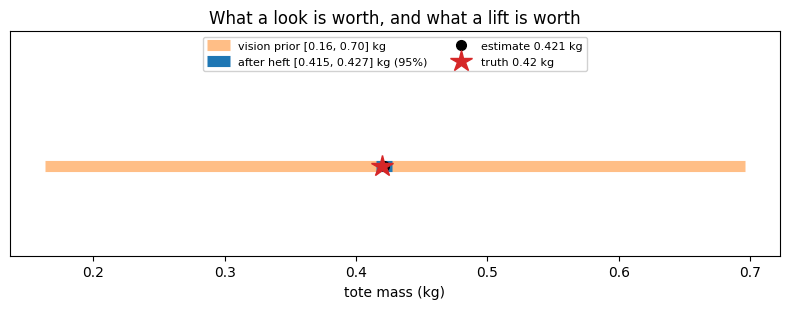

prior width  : 0.533 kg
posterior CI : 0.013 kg  (42x tighter)
error vs truth: 1.2 g


In [11]:
mass = enrollment.identification.params["tote.mass"]
ci_lo, ci_hi = enrollment.identification.intervals["tote.mass"]

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(
    [lo, hi],
    [1, 1],
    lw=8,
    color="tab:orange",
    alpha=0.5,
    solid_capstyle="butt",
    label=f"vision prior [{lo:.2f}, {hi:.2f}] kg",
)
ax.plot(
    [ci_lo, ci_hi],
    [1, 1],
    lw=8,
    color="tab:blue",
    solid_capstyle="butt",
    label=f"after heft [{ci_lo:.3f}, {ci_hi:.3f}] kg (95%)",
)
ax.plot([mass], [1], "o", color="k", ms=7, label=f"estimate {mass:.3f} kg")
ax.plot(
    [PLANTED_MASS_KG],
    [1],
    "*",
    color="tab:red",
    ms=16,
    label=f"truth {PLANTED_MASS_KG} kg",
)
ax.set_yticks([])
ax.set_ylim(0.4, 1.9)
ax.set_xlabel("tote mass (kg)")
ax.set_title("What a look is worth, and what a lift is worth")
ax.legend(fontsize=8, loc="upper center", ncol=2, framealpha=0.9)
fig.tight_layout()
plt.show()

print(f"prior width  : {hi - lo:.3f} kg")
print(
    f"posterior CI : {ci_hi - ci_lo:.3f} kg  "
    f"({(hi - lo) / (ci_hi - ci_lo):.0f}x tighter)"
)
print(f"error vs truth: {abs(mass - PLANTED_MASS_KG) * 1000:.1f} g")

*Figure 4 — the mass bracket a vision model can supply (orange) against the interval a
0.2-second heft produces (blue), with the estimate and the planted truth. The prior
bounds the search; the telemetry does the measuring.*

The gate also has teeth, which is easy to forget when every example passes. The same
object, the same base, the same probe — from the extended pose:

In [12]:
refused = vet_probe(
    twin.robot,
    payload,
    prior,
    StabilityConstraint(base=LEKIWI_BASE),
    speeds=(0.30, 0.10),
    pose_rad=POSE_EXTENDED,
)

print(f"approved: {refused.approved}")
print(refused.detail)
print()
print("attempts (speed rad/s -> worst-case margin mm):")
for speed, margin in refused.attempts:
    print(f"  {speed:.2f} -> {margin * 1000:7.1f}")

approved: False
no probe approved: the best candidate (0.1 rad/s) still leaves -59.5 mm, under the 20.0 mm floor, with the prior's heaviest object (0.696 kg)

attempts (speed rad/s -> worst-case margin mm):
  0.30 ->   -62.5
  0.10 ->   -59.5


> **Measured, not assumed:** slowing the probe barely helps. Across 0.10–0.30 rad/s the
> worst-case margin moves under a millimetre, while moving the *pose* moves it by tens of
> millimetres. So the speed sweep in `vet_probe` is a fine adjustment, and a refusal
> means "re-pose the arm", which is what the message says. We found this by asserting the
> opposite in a test and watching it fail.

`enroll_object` **raises** in this situation rather than probing slowly and hoping — the
one thing a safety gate must not do is proceed at reduced confidence without saying so.

## 7. The reflex: what actually reaches the actuators

Everything so far happens *before* motion. But a permitted plan is not a safe execution:
the policy still emits torques tick by tick, and a veto has to hand over to something.
That organ is `ReflexController` — a safety filter that solves, every tick,

$$\min_{\boldsymbol\tau} \ \tfrac12\lVert \boldsymbol\tau - \boldsymbol\tau_{\text{des}}\rVert^2
\quad \text{s.t.} \quad \dot h_j(\mathbf x, \boldsymbol\tau) + \alpha_j h_j(\mathbf x) \ge 0 \ \forall j,
\quad \lvert \tau_i\rvert \le \tau_i^{\max}. \tag{7}$$

Stay as close as possible to what the policy asked for, subject to every barrier. Two
implementation choices matter:

- **One pass for value and derivative.** $h$ and $\dot h$ come from a single
  `jax.jvp` of $h$ along $\dot{\mathbf x} = f(\mathbf x, \boldsymbol\tau)$ — dual-number
  arithmetic, not a second evaluation and not a hand-derived Lie derivative.
- **Fixed budget.** A fixed number of relinearizations, each with a fixed number of dual
  projected-gradient iterations: no data-dependent branches, no adaptive termination.
  Cost per tick is the same arithmetic every tick, which is the property a
  worst-case-execution-time bound needs later (we do not have that bound; see §9).

The rows come from *this unit's measured twin*, which is the part a kinematic filter
cannot have.

In [13]:
reflex = ReflexController(unit, envelope)
q_rest = np.array(POSE_TUCKED)
qd_rest = np.zeros(n)
T_rest = np.full(n, unit.T_amb)

print(f"barrier rows: {reflex.n_rows}")
print(
    f"  {n} joint upper + {n} joint lower + {n} velocity  (kinematic — any filter has these)"
)
print(
    f"  {n} servo thermal + 1 bus voltage                  (measured — this unit's fit)"
)
print()
values = reflex.barrier_values(q_rest, qd_rest, T_rest)
for row in (
    "joint_upper[shoulder_lift]",
    "joint_velocity[elbow_flex]",
    "servo_temperature[servo_0]",
):
    print(f"  h[{row:28s}] = {values[row]:8.3f}   (safe where positive)")

barrier rows: 25
  6 joint upper + 6 joint lower + 6 velocity  (kinematic — any filter has these)
  6 servo thermal + 1 bus voltage                  (measured — this unit's fit)



  h[joint_upper[shoulder_lift]  ] =    2.895   (safe where positive)
  h[joint_velocity[elbow_flex]  ] =  100.000   (safe where positive)
  h[servo_temperature[servo_0]  ] =   45.000   (safe where positive)


Now the derivation promised in §2. Take the thermal barrier $h = T_{\text{ceil}} - T$, so
$\dot h = -\dot T$, and substitute the thermal model (3) into the barrier condition (1)
with the gain set to the servo's own time constant, $\alpha = 1/\tau_{th}$:

$$-\frac{T_{ss}(\tau) - T}{\tau_{th}} \;+\; \frac{T_{\text{ceil}} - T}{\tau_{th}} \;\ge\; 0
\qquad \Longleftrightarrow \qquad T_{ss}(\tau) \;\le\; T_{\text{ceil}}. \tag{8}$$

The $T$ cancels. With that gain the thermal row *is* the sustained-hold criterion — the
same one `SafetyMonitor` vetoes on — which is why the gate and the reflex cannot disagree
about where the thermal edge is. Inverting (3) gives the largest torque the servo can
hold forever:

$$\tau_{\max} = \sqrt{\frac{T_{\text{ceil}} - T_{\text{amb}}}{k_{pwr} R_{th}}}. \tag{9}$$

That is a closed-form prediction of what the filter should output for any over-hot
request. Let us check the solver against it.

> **Why not one $\alpha$ for everything?** Because $\alpha$ bounds how fast a barrier may
> close, and it has units of 1/s. At the mechanical rows' $\alpha = 5\ \text{s}^{-1}$, a
> servo 2 K below its ceiling would be permitted to heat at 10 K/s — no clamp at all on a
> state whose time constant is a minute. Per-row gains are not a refinement here; a
> single gain is simply wrong.

In [14]:
OVER_TAU = 1.8  # N.m per joint — an over-hot request from userland

decision = reflex.filter(q_rest, qd_rest, T_rest, np.full(n, OVER_TAU))
tau_analytic = float(
    np.sqrt((CEILING_K - unit.T_amb) / (float(unit.k_pwr[0]) * float(unit.R_th[0])))
)

print(f"policy asked for  : {OVER_TAU:.4f} N.m per joint")
print(f"reflex returned   : {decision.tau[0]:.4f} N.m per joint")
print(f"equation (9) says : {tau_analytic:.4f} N.m")
print(f"agreement         : {abs(decision.tau[0] - tau_analytic) * 1e3:.3f} mN.m")
print()
print(
    f"engaged={decision.engaged}  feasible={decision.feasible}  "
    f"binding={decision.binding_constraint}"
)
print(decision.detail)

policy asked for  : 1.8000 N.m per joint
reflex returned   : 1.3693 N.m per joint
equation (9) says : 1.3693 N.m
agreement         : 0.000 mN.m

engaged=True  feasible=True  binding=servo_temperature[servo_0]
clamped by servo_temperature[servo_0] (slack -9.53e-08); |Δτ| = 0.431 N·m


The solver lands on the closed-form answer to within a fraction of a milli-newton-metre —
a satisfying check, because nothing in the QP knows about equation (9); it only knows the
barrier rows and the twin.

A filter that clamps correctly at one state is not yet evidence that it *holds an
envelope*. The evidence is closed-loop: run the same over-hot command through the twin
with and without the filter, for long enough that the thermal state matters.

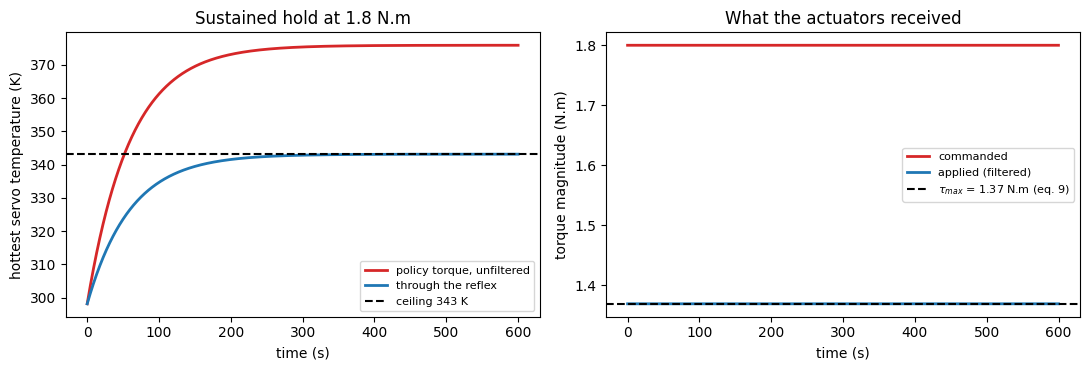

unfiltered peak : 375.9 K  (CROSSES the 343 K ceiling)
filtered peak   : 343.1 K  (stays under it)
headroom kept   : 2 mK (the barrier asymptotes to the ceiling by construction)


In [15]:
HOLD_S = 600.0  # 10 minutes of sustained hold — 10x the servo thermal time constant
DT_THERMAL = 0.2

dynamics = twin.robot.functional_dynamics()  # build the MJX model once, not per step
heat = jax.jit(
    lambda q, qd, T, tau: unit.state_derivative(q, qd, T, tau, dynamics=dynamics)[2]
)


def held_pose_hold(tau_cmd, *, filtered):
    """Heat a position-held unit under `tau_cmd`, optionally filtering each tick."""
    q = jnp.asarray(q_rest)
    qd = jnp.asarray(qd_rest)
    T = jnp.asarray(T_rest)
    trace, applied = [float(T.max())], []
    for _ in range(int(HOLD_S / DT_THERMAL)):
        tau = np.full(n, tau_cmd)
        if filtered:
            tau = reflex.filter(q, qd, T, tau).tau
        applied.append(float(np.max(np.abs(tau))))
        T = T + DT_THERMAL * heat(q, qd, T, jnp.asarray(tau))
        trace.append(float(T.max()))
    return np.asarray(trace), np.asarray(applied)


raw, raw_tau = held_pose_hold(OVER_TAU, filtered=False)
filt, filt_tau = held_pose_hold(OVER_TAU, filtered=True)
t_hold = np.arange(len(raw)) * DT_THERMAL

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(t_hold, raw, lw=2, color="tab:red", label="policy torque, unfiltered")
axes[0].plot(t_hold, filt, lw=2, color="tab:blue", label="through the reflex")
axes[0].axhline(
    CEILING_K, color="k", ls="--", lw=1.5, label=f"ceiling {CEILING_K:.0f} K"
)
axes[0].set_xlabel("time (s)")
axes[0].set_ylabel("hottest servo temperature (K)")
axes[0].set_title(f"Sustained hold at {OVER_TAU} N.m")
axes[0].legend(fontsize=8, loc="lower right")

axes[1].plot(t_hold[:-1], raw_tau, lw=2, color="tab:red", label="commanded")
axes[1].plot(t_hold[:-1], filt_tau, lw=2, color="tab:blue", label="applied (filtered)")
axes[1].axhline(
    tau_analytic,
    color="k",
    ls="--",
    lw=1.5,
    label=rf"$\tau_{{max}}$ = {tau_analytic:.2f} N.m (eq. 9)",
)
axes[1].set_xlabel("time (s)")
axes[1].set_ylabel("torque magnitude (N.m)")
axes[1].set_title("What the actuators received")
axes[1].legend(fontsize=8, loc="center right")
fig.tight_layout()
plt.show()

print(
    f"unfiltered peak : {raw.max():.1f} K  "
    f"({'CROSSES' if raw.max() > CEILING_K else 'stays under'} the {CEILING_K:.0f} K ceiling)"
)
print(
    f"filtered peak   : {filt.max():.1f} K  "
    f"({'CROSSES' if filt.max() > CEILING_K else 'stays under'} it)"
)
print(
    f"headroom kept   : {(CEILING_K - filt.max()) * 1e3:.0f} mK (the barrier asymptotes to the ceiling by construction)"
)

*Figure 5 — left: the hottest servo's temperature over a ten-minute hold, with and
without the filter in the torque path; the dashed line is the declared ceiling. Right:
the torque that actually reached the actuators, against the closed-form sustainable
torque of equation (9).*

This is the claim in its strongest form: **same command, same unit, one difference**. The
unfiltered policy walks the servo through its ceiling and keeps going. The filtered one
asymptotes just underneath, because the barrier's steady-state reading of the thermal
model *is* the ceiling. Nothing retrained the policy; the filter sits between it and the
bus.

Before believing a closed-loop result, run the generic controller diagnostics on it. Two
questions matter here: is the actuator pinned at a rail (usually a tuning bug), and is
the signal chattering (usually a sign error)?

In [16]:
sat = analyze_saturation(
    filt_tau,
    lower=0.0,
    upper=tau_analytic,
    mode="upper_only",
    name="reflex output",
    warn=False,
)
osc = analyze_control_oscillation(
    filt_tau - filt_tau.mean(),
    t_hold[:-1],
    name="reflex output",
    warn=False,
)
print(f"saturated at the clamp : {sat.fraction_at_upper:.0%} of the hold")
print(
    f"sign changes           : {osc.crossings_per_second:.3f} /s "
    f"(bang-bang starts around 5/s)"
)
print(
    f"warnings triggered     : saturation={sat.warning_triggered}, "
    f"oscillation={osc.warning_triggered}"
)

saturated at the clamp : 100% of the hold
sign changes           : 0.435 /s (bang-bang starts around 5/s)
warnings triggered     : saturation=True, oscillation=False


The saturation diagnostic fires, and here that is **correct behaviour rather than a
tuning bug**: the reflex is *supposed* to sit on its limit when userland is asking for
more than the unit can take — the whole point is that it holds the edge instead of
tracking the request. What would be alarming is the other number, and it is clean: the
filtered command has essentially no sign changes, so the clamp is a smooth saturation and
not the chattering a mis-signed barrier would produce.

> **Read diagnostics in context.** A generic "actuator saturated 100 % of the time"
> warning means one thing for a PD controller and the opposite for a safety filter.
> Silently accepting a warning is not acceptable; explaining why it is expected is.

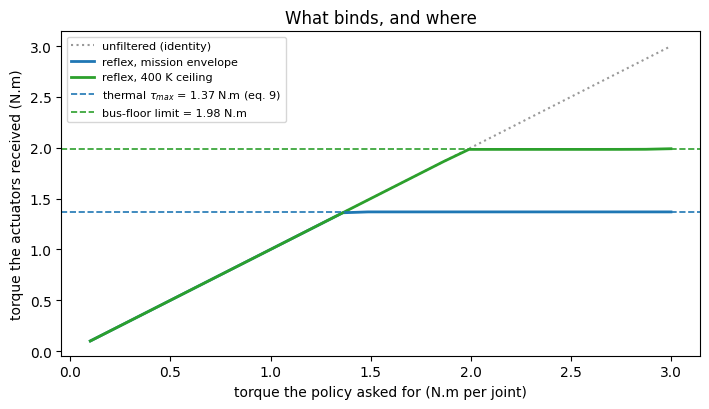

ceiling 343 K (mission)  clamps at 1.369 N.m; rows seen: ['joint_lower[gripper]', 'servo_temperature[servo_0]']
ceiling 400 K            clamps at 1.991 N.m; rows seen: ['bus_voltage', 'joint_lower[gripper]']
thermal closed form (eq. 9, 400 K): 2.060 N.m  -- but the bus binds first at 1.984 N.m


In [17]:
# Which row binds, as the policy asks for more? Same unit, same filter, two declared
# ceilings -- and the physics that stops you changes.
mission = reflex  # ceiling 343.15 K, bus floor 11.0 V
hot_ceiling = ReflexController(
    unit,
    SafetyEnvelope(
        temp_ceiling_k=400.0, bus_floor_v=BUS_FLOOR_V, torque_margin_frac=TORQUE_FRAC
    ),
)

commands = np.linspace(0.1, 3.0, 24)
applied = {"ceiling 343 K (mission)": [], "ceiling 400 K": []}
binding = {"ceiling 343 K (mission)": [], "ceiling 400 K": []}
for label, ctrl in (
    ("ceiling 343 K (mission)", mission),
    ("ceiling 400 K", hot_ceiling),
):
    for cmd in commands:
        d = ctrl.filter(q_rest, qd_rest, T_rest, np.full(n, cmd))
        applied[label].append(float(np.max(np.abs(d.tau))))
        binding[label].append(d.binding_constraint)

# The bus floor has a closed form too: V_oc - R_int * sum_i k_i |tau| = V_floor.
tau_bus = float((float(unit.V_oc) - BUS_FLOOR_V) / (float(unit.R_int) * sum(unit.k_i)))
tau_hot = float(
    np.sqrt((400.0 - unit.T_amb) / (float(unit.k_pwr[0]) * float(unit.R_th[0])))
)

fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(commands, commands, color="0.6", ls=":", label="unfiltered (identity)")
ax.plot(
    commands,
    applied["ceiling 343 K (mission)"],
    lw=2,
    color="tab:blue",
    label="reflex, mission envelope",
)
ax.plot(
    commands,
    applied["ceiling 400 K"],
    lw=2,
    color="tab:green",
    label="reflex, 400 K ceiling",
)
ax.axhline(
    tau_analytic,
    color="tab:blue",
    ls="--",
    lw=1.2,
    label=rf"thermal $\tau_{{max}}$ = {tau_analytic:.2f} N.m (eq. 9)",
)
ax.axhline(
    tau_bus,
    color="tab:green",
    ls="--",
    lw=1.2,
    label=rf"bus-floor limit = {tau_bus:.2f} N.m",
)
ax.set_xlabel("torque the policy asked for (N.m per joint)")
ax.set_ylabel("torque the actuators received (N.m)")
ax.set_title("What binds, and where")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

for label in applied:
    rows = sorted(set(binding[label]))
    print(f"{label:24s} clamps at {max(applied[label]):.3f} N.m; rows seen: {rows}")
print(
    f"thermal closed form (eq. 9, 400 K): {tau_hot:.3f} N.m  -- but the bus binds first "
    f"at {tau_bus:.3f} N.m"
)

*Figure 6 — the filter's input-output curve. Below the limit the policy passes through
untouched (the line sits on the identity); above it, the applied torque saturates at a
value nothing in the QP was told: the closed-form thermal limit of equation (9) for the
mission envelope, and the bus-floor limit
$\tau = (V_{oc} - V_{\text{floor}})/(R_{int}\sum_i k_i)$ once the ceiling is raised out of
the way.*

That green curve is the multi-physics point in one picture. Nothing about the arm
changed — the *declared* thermal ceiling moved, and a completely different physical
mechanism (the shared battery sagging under six servos' current) became the thing that
stops you. An analytic limit set written against joint kinematics has no way to express
either bound, let alone which one is active today.

> **What if two rows genuinely conflict?** They can: stopping before a joint limit may
> need more braking torque than the servo can sustain, and then no torque satisfies both.
> On *this* arm it does not happen at ordinary speeds — gravity and MuJoCo's own joint
> limit constraint decelerate these light links before the barrier has to spend torque —
> but on a heavier plant it does, and the reflex resolves it by *declared* priority: the
> stop wins, the thermal budget is spent, and `decision.detail` names the row that
> yielded. The reproducible case is
> `test/selfcheck/test_reflex.py::test_a_stop_outranks_the_thermal_budget_and_says_so`.

Finally, arbitration. `SimplexSwitch` puts the gate and the reflex in one path: the
monitor judges the forecast, and the reflex is always in the torque path — a clear
forecast is not a promise about *this* tick.

In [18]:
monitor = SafetyMonitor(unit, envelope)
switch = SimplexSwitch(monitor, reflex)


def one_tick(tau_cmd, label):
    tau = np.full(n, tau_cmd)
    prediction = unit.rollout(
        jnp.asarray(q_rest),
        jnp.asarray(qd_rest),
        jnp.asarray(T_rest),
        jnp.asarray(tau)[None, :],
        0.005,
    )
    step = switch.step(prediction, q_rest, qd_rest, T_rest, tau)
    print(
        f"{label:22s} cmd {tau_cmd:5.2f} -> mode {step.mode:7s} "
        f"applied {np.max(np.abs(step.tau)):5.3f} N.m   ({step.safety.binding_constraint})"
    )
    return step


print("userland command      gate verdict and what the actuators got")
print("-" * 78)
one_tick(0.05, "gentle")
one_tick(1.30, "near the edge")
one_tick(3.00, "reckless")

userland command      gate verdict and what the actuators got
------------------------------------------------------------------------------


gentle                 cmd  0.05 -> mode pass    applied 0.050 N.m   (servo_temperature)


near the edge          cmd  1.30 -> mode derate  applied 0.523 N.m   (bus_voltage)


reckless               cmd  3.00 -> mode reflex  applied 0.000 N.m   (servo_temperature)


SimplexDecision(mode='reflex', tau=array([0., 0., 0., 0., 0., 0.]), safety=SafetyDecision(action=<SafetyAction.VETO: 'veto'>, factor=0.0, binding_constraint='servo_temperature', worst_value=514.15, time_to_breach_s=14.016891070890313, detail='veto: servo_temperature binding (worst 514) in 14.0 s', factors={'servo_temperature': 0.0, 'bus_voltage': 0.0, 'torque': 1.0}, worst_values={'servo_temperature': 514.15, 'bus_voltage': 10.4029, 'torque': 0.3}), reflex=ReflexDecision(tau=array([0., 0., 0., 0., 0., 0.]), tau_desired=array([-0., -0., -0., -0., -0., -0.]), engaged=False, binding_constraint='joint_lower[gripper]', slack=0.6226649999999999, violation=0.0, barriers={'joint_upper[shoulder_pan]': 1.8698599999999999, 'joint_upper[shoulder_lift]': 2.89533, 'joint_upper[elbow_flex]': 2.44, 'joint_upper[wrist_flex]': 1.60806, 'joint_upper[wrist_roll]': 2.79121, 'joint_upper[gripper]': 1.69533, 'joint_lower[shoulder_pan]': 1.8698599999999999, 'joint_lower[shoulder_lift]': 0.49533000000000005, '

Three modes, one code path: **pass** (the command goes through the filter untouched),
**derate** (scaled by the monitor's factor, then filtered), and **reflex** (userland's
command is dropped and the recovery brake runs — itself filtered, so the stop cannot cook
a servo on the way to standstill).

## 8. What makes this different from the alternatives

Every ingredient here exists somewhere. The composition is the claim, so it is worth
being precise about what each neighbouring approach does and does not give you.

| Approach | What it enforces | What it cannot express |
|---|---|---|
| Joint-limit / collision filters (the standard CBF-QP) | Kinematic limits, from spec | Anything not in the URDF: this servo's heat, this pack's sag, this base's tip-over |
| Camera-based external monitors | Geometric proximity, from outside the robot | Internal state; and they stop at the fence, not at the actuator |
| Learned residual models (SAGE-class) | Compensate a modelling gap | An envelope: a residual net has no ceiling, no floor, and no statement of its own ignorance |
| Rule-based analytic safety layers | Closed-form limit sets | Multi-physics cascades — *hold → heat → current → bus sag → brownout* is a rollout, not an inequality |
| **This layer** | Barriers built from the **measured** unit, checked by simulation, with the parameters' uncertainty carried through | (see §9 — the list is real) |

Three properties fall out of that table, and they are what to remember:

1. **The constraints are per-unit and measured.** `R_th`, `V_oc`, the joint friction — a
   nominal-spec kernel is security theatre, because the whole question is whether *this*
   machine, at *this* age, survives the command.
2. **The verdict is simulative, not analytic.** That is what lets a hold be vetoed by a
   thermal-then-electrical cascade no single inequality captures.
3. **Uncertainty is a first-class output.** The gate takes the worst case; the oracle
   hands you the whole distribution, so you can tell "physics says no" from "measure
   more". Conservatism you can price is conservatism you can shrink.

## 9. Failure modes — where this breaks, specifically

- **No measured worst-case execution time.** The reflex's arithmetic is fixed-cost and
  branch-free by construction, and it runs in ~0.2 ms per tick on a workstation for a
  2-DOF twin — but a *bound* needs the lowered, compiled build, not a Python measurement.
  Do not put this in a certification argument yet.
- **Declared braking authority.** `brake_decel` in equation (2) is asserted, not
  identified. Overstate it and the joint barrier becomes optimistic — the one direction in
  which this filter can be wrong unsafely.
- **The posterior covers off-body leaves only.** Thermal, actuation scale, battery. Body
  and payload uncertainty are *not* sampled axes; a payload's interval enters the
  enrollment lane as a worst case instead. A wide payload CI therefore does not widen the
  oracle's tip-over band.
- **Fixed-step integration.** The twin integrates with fixed-step RK4. A free-swinging arm
  diverges above ~10 ms *even at zero torque*; `simulate_plan` raises rather than
  reporting margins computed from `nan`, but a bare `Twin.rollout` will hand you the NaNs.
- **The tip-over screen reads a joint trajectory in DOF order.** Floating-base and
  ball-joint models are not covered, and the ZMP is quasi-dynamic with perfect tracking
  assumed — the margin floor carries that budget.
- **A semantic prior is a declared guess.** A confidently wrong bracket pins the estimate
  to its own edge. The result names the pinned parameter, but nothing here validates the
  guess; no real vision model has been asked for a bracket yet.
- **The grasp is a rigid weld.** Gripper compliance is unmodelled, so a soft grasp
  contaminates the heft (the object reads lighter and springier than it is).
- **Sim-tier throughout this notebook.** The heft is a seeded loopback with a planted
  mass, and the base profile is representative geometry, not a measured unit. The
  *ordering* of these verdicts is trustworthy well before the absolute margins are.

## 10. Exercises

1. **Buy back performance by measuring.** Halve `R_TH_STD` and `K_PWR_STD` and re-run
   §4. What happens to `pass_fraction` and to the width of the $T_{ss}$ histogram? At what
   uncertainty does the carry become a clean pass? This is the margin dividend, measured.

2. **Break the filter honestly.** Raise `alpha_thermal` when constructing the
   `ReflexController` (e.g. `alpha_thermal=10.0 / (R_th * C_th)`) and re-run the
   closed-loop hold. Predict *before running* whether the filtered trace crosses the
   ceiling, then check. Explain the result using equation (8).

3. **Find the pose boundary.** Sweep `shoulder_lift` from −1.6 to 0 rad, recompute the
   worst ZMP margin for the gentle command, and plot margin against pose. Where does the
   20 mm floor bite? Compare that lever with the probe-speed lever from §6.

4. **Make the prior wrong.** Re-run §6 with a `SemanticPrior` bracketing 0.02–0.05 kg
   ("foam replica"). Check `enrollment.identification.warnings`: which parameter is
   pinned, and what does the recipe name say? Then argue whether the pipeline behaved
   correctly.

5. **Open-ended: add a row.** The tip-over margin is screened by the oracle over a
   rollout, but it is not a barrier row in the reflex — so nothing enforces it at tick
   rate. Sketch (or implement) a ZMP barrier: what is $h$, what is its relative degree in
   $\boldsymbol\tau$, and what would you have to differentiate that today's numpy ZMP path
   does not?

## 11. Key takeaways

- **Three horizons, three organs.** MPC simulates to choose, the gate simulates to
  permit, the oracle simulates to answer — and the reflex enforces at tick rate. They are
  not variations on one thing.
- **The measured twin is what makes enforcement real.** Thermal ceilings, bus floors and
  tip-over margins come from *this unit's* fit; a nominal model cannot state them.
- **Dispersion is the honest part of an answer.** Worst case tells you what a gate will
  do; the pass fraction tells you how much of that is your own ignorance.
- **A guess can be load-bearing if it is bounded and declared.** A vision prior vets the
  probe against its heaviest case, seeds the fit, bounds the search — and is recorded in
  the provenance so a seeded fit never reads as a pure measurement.
- **With $\alpha = 1/\tau_{th}$ the thermal barrier is the sustained-hold criterion.** Gate
  and reflex cannot disagree about the thermal edge, and the clamp matches the closed-form
  $\tau_{\max}$.
- **The binding physics changes with the declared envelope.** Same arm, same filter:
  raise the thermal ceiling and the shared battery becomes what stops you. A kinematic
  limit set cannot express either bound.
- **When barriers genuinely conflict, someone has to yield** — the reflex resolves it by
  a declared priority and names the row that yielded, rather than picking silently.

**Next steps:** [`selfcheck_demo_lekiwi.ipynb`](selfcheck_demo_lekiwi.ipynb) for the
predict-and-veto chain on real telemetry; [`same_pixels_different_physics.ipynb`](same_pixels_different_physics.ipynb)
for the object-identification lane in depth; `jaxterity mcp serve` to call
`oracle_simulate_plan` / `oracle_what_if` / `oracle_identify_payload` from an LLM planner;
and `KNOWN_GAPS.md` §Per-unit twin for the full, current list of what this layer does not
yet do.

## References

- Ames et al., *Control Barrier Functions: Theory and Applications*, ECC 2019 — the
  standard reference for condition (1) and class-$\mathcal{K}$ gains.
- *Acc-CBF-QP* — [arXiv:2607.14488](https://arxiv.org/abs/2607.14488). Clamping an
  arbitrary policy to joint position/velocity/torque limits at execution time without
  retraining; the source of the braking-distance shape in equation (2), and of the
  hardware violation-rate metric this layer has not yet measured.
- *Dual-algebraic CBFs* — [arXiv:2606.25333](https://arxiv.org/abs/2606.25333). Barrier
  value and derivative in one pass via dual numbers, at overhead independent of state
  dimension — the arithmetic profile §7 follows with `jax.jvp`.
- *RigPI* — [arXiv:2606.25212](https://arxiv.org/abs/2606.25212), IROS 2026. Semantic
  priors from a vision-language model to initialize and bound inertial identification;
  the idea behind §6's bracket.
- Vukobratović & Borovac, *Zero-Moment Point — Thirty-Five Years of Its Life*, IJHR 2004 —
  equation (5) and what it does and does not guarantee.
- The layer's own evidence ledger: `CLAIMS.md` rows C-129 (reflex), C-130/C-131 (oracle),
  C-132 (enrollment), each pointing at the test that runs in CI.